In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

In [3]:
data = {
    "Patient_ID":[
        'P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008',
        'P009', 'P010', 'P011', 'P012', 'P013', 'P014', 'P015', 'P016',
        'P017', 'P018', 'P019', 'P020'
   ],
    "Age": [
        47, 62, 32, 73, 53, 33, 31, 56, 22, 25,
        45, 53, 70, 28, 49, 65, 76, 76, 72, 75
   ],
    "Gender":[
        'Male', 'Female', 'Female', 'Female', 'Female', 'Female', 'Female', 'Female',
        'Female', 'Male', 'Male', 'Male', 'Male', 'Female', 'Female', 'Female',
        'Male', 'Female', 'Male', 'Female'
  ],
    "Blood_Pressure":[
        136, 137, 105, 149, 135, 117, 115, 134, 111, 110,
        141, 139, 146, 108, 119, 143, 149, 147, 137, 143
  ],
    "Heart_Rate":[
        69, 72, 72, 84, 71, 68, 78, 79, 66, 78,
        84, 74, 76, 78, 77, 75, 74, 76, 77, 73
  ],
    "Department": [
        'Cardiology', 'Neurology', 'General Medicine', 'Neurology', 'General Medicine', 'Cardiology', 'Orthopedics', 'General Medicine',
        'Orthopedics', 'Neurology', 'General Medicine', 'Neurology', 'General Medicine', 'Cardiology', 'Cardiology', 'Cardiology',
        'Cardiology', 'Neurology', 'General Medicine', 'General Medicine'
  ],
    "Appointment_Date":[
         '2026-01-05', '2026-01-23', '2026-02-12', '2026-02-13', '2026-02-19',
        '2026-03-03', '2026-03-11', '2026-03-27', '2026-03-31', '2026-04-03',
        '2026-04-06', '2026-04-14', '2026-04-15', '2026-04-22', '2026-05-15',
        '2026-05-25', '2026-05-26', '2026-05-29', '2026-06-09', '2026-06-12'
    ]
}

df = pd.DataFrame(data)
display(df)

,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Department,Appointment_Date
0,P001,47,Male,136,69,Cardiology,2026-01-05
1,P002,62,Female,137,72,Neurology,2026-01-23
2,P003,32,Female,105,72,General Medicine,2026-02-12
3,P004,73,Female,149,84,Neurology,2026-02-13
4,P005,53,Female,135,71,General Medicine,2026-02-19
5,P006,33,Female,117,68,Cardiology,2026-03-03
6,P007,31,Female,115,78,Orthopedics,2026-03-11
7,P008,56,Female,134,79,General Medicine,2026-03-27
8,P009,22,Female,111,66,Orthopedics,2026-03-31
9,P010,25,Male,110,78,Neurology,2026-04-03


In [4]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins = [17,30,45,60,80],
    labels = ["18-30", "31-45", "46-60", "61-80"]
).astype(str)

df["BP_Category"] = pd.cut(
    df["Blood_Pressure"],
    bins = [0, 119, 139, 300],
    labels = ["Normal", "Elevated", "High"]
)

display(df.head())

,Patient_ID,Age,Gender,Blood_Pressure,Heart_Rate,Department,Appointment_Date,Age_Group,BP_Category
0,P001,47,Male,136,69,Cardiology,2026-01-05,46-60,Elevated
1,P002,62,Female,137,72,Neurology,2026-01-23,61-80,Elevated
2,P003,32,Female,105,72,General Medicine,2026-02-12,31-45,Normal
3,P004,73,Female,149,84,Neurology,2026-02-13,61-80,High
4,P005,53,Female,135,71,General Medicine,2026-02-19,46-60,Elevated


In [5]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(20, 9)


In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Patient_ID        20 non-null     object  
 1   Age               20 non-null     int64   
 2   Gender            20 non-null     object  
 3   Blood_Pressure    20 non-null     int64   
 4   Heart_Rate        20 non-null     int64   
 5   Department        20 non-null     object  
 6   Appointment_Date  20 non-null     object  
 7   Age_Group         20 non-null     object  
 8   BP_Category       20 non-null     category
dtypes: category(1), int64(3), object(5)
memory usage: 1.5+ KB


In [7]:
print("\nDescriptive Statistics:")
display(df[["Age", "Blood_Pressure", "Heart_Rate"]].describe())


Descriptive Statistics:


,Age,Blood_Pressure,Heart_Rate
count,20.000000,20.000000,20.000000
mean,52.150000,131.050000,75.050000
std,18.669635,15.122221,4.706938
min,22.000000,105.000000,66.000000
25%,32.750000,116.500000,72.000000
50%,53.000000,136.500000,75.500000
75%,70.500000,143.000000,78.000000
max,76.000000,149.000000,84.000000


In [8]:
print("\nGender-wise Patient Count:")
print(df["Gender"].value_counts())


Gender-wise Patient Count:
Gender
Female    13
Male       7
Name: count, dtype: int64


In [9]:
print("\nDepartment-wise Patient Count:")
print(df["Department"].value_counts())


Department-wise Patient Count:
Department
General Medicine    7
Cardiology          6
Neurology           5
Orthopedics         2
Name: count, dtype: int64


In [10]:
print("\nBlood Pressure Category Count:")
print(df["BP_Category"].value_counts().reindex(["Normal", "Elevated", "High"]))


Blood Pressure Category Count:
BP_Category
Normal      7
Elevated    6
High        7
Name: count, dtype: int64


In [11]:
print("\nMissing Values per Column:")      #NOT NEEDED SINCE NO MISSING VALUES
print(df.isnull().sum())


Missing Values per Column:
Patient_ID          0
Age                 0
Gender              0
Blood_Pressure      0
Heart_Rate          0
Department          0
Appointment_Date    0
Age_Group           0
BP_Category         0
dtype: int64


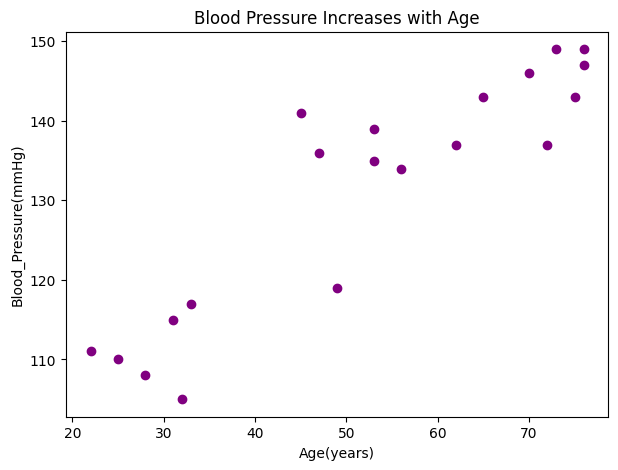

In [12]:
plt.figure(figsize=(7,5))
plt.scatter(df["Age"], df["Blood_Pressure"], color="purple")
plt.xlabel("Age(years)")
plt.ylabel("Blood_Pressure(mmHg)")
plt.title("Blood Pressure Increases with Age")
plt.show()

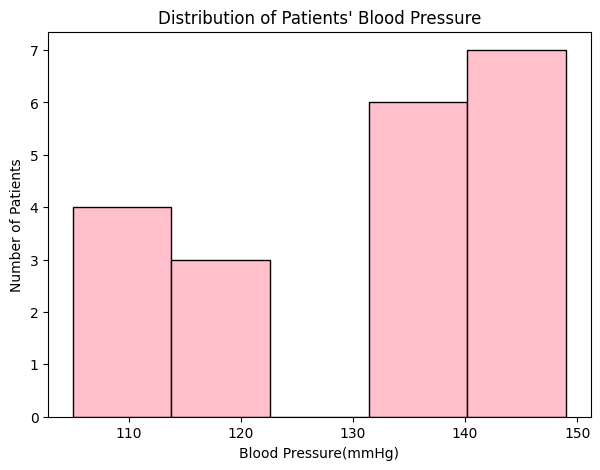

In [13]:
plt.figure(figsize=(7,5))
plt.hist(df["Blood_Pressure"], bins=5, color="pink", edgecolor="black")
plt.xlabel("Blood Pressure(mmHg)")
plt.ylabel("Number of Patients")
plt.title("Distribution of Patients' Blood Pressure")
plt.show()

Correlation Matrix:


,Age,Blood_Pressure,Heart_Rate
Age,1.00,0.91,0.23
Blood_Pressure,0.91,1.00,0.26
Heart_Rate,0.23,0.26,1.00


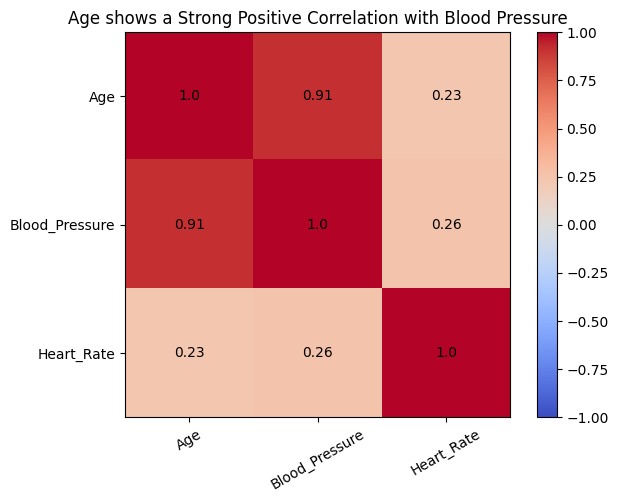

In [14]:
correlation = df[["Age", "Blood_Pressure", "Heart_Rate"]].corr()

print("Correlation Matrix:")
display(correlation.round(2))

plt.figure(figsize=(7, 5))
plt.imshow(correlation, cmap="coolwarm", vmin = -1, vmax = 1)
plt.colorbar()

plt.xticks([0,1,2], ["Age", "Blood_Pressure", "Heart_Rate"], rotation=30)
plt.yticks([0,1,2], ["Age", "Blood_Pressure", "Heart_Rate"])

for i in range(3):
  for j in range(3):
    plt.text(j,i, round(correlation.iloc[i,j], 2),
             ha="center", va="center")

plt.title("Age shows a Strong Positive Correlation with Blood Pressure")
plt.show()

In [15]:
gender_summary = df.groupby("Gender").agg(
    Average_Age = ("Age", "mean"),
    Average_BP = ("Blood_Pressure", "mean"),
    Average_Heart_Rate = ("Heart_Rate", "mean"),
    Patient_Count = ("Patient_ID", "count")
).round(2)

print("Gender-wise Patient Summary:")
display(gender_summary)


age_summary = df.groupby("Age_Group").agg(
    Average_BP = ("Blood_Pressure", "mean"),
    Average_Heart_Rate = ("Heart_Rate", "mean"),
    Patient_Count = ("Patient_ID", "count")
).round(2)

print("\nAge Group-wise Patient Summary:")
display(age_summary)


dept_summary = df.groupby("Department").agg(
    Average_BP = ("Blood_Pressure", "mean"),
    Patient_Count = ("Patient_ID", "count")
).round(2)

print("\nDepartment-wise Summary:")
display(dept_summary)

Gender-wise Patient Summary:


,Average_Age,Average_BP,Average_Heart_Rate,Patient_Count
Gender,,,,
Female,50.38,127.92,74.54,13
Male,55.43,136.86,76.00,7



Age Group-wise Patient Summary:


,Average_BP,Average_Heart_Rate,Patient_Count
Age_Group,,,
18-30,109.67,74.00,3
31-45,119.50,75.50,4
46-60,132.60,74.00,5
61-80,143.88,75.88,8



Department-wise Summary:


,Average_BP,Patient_Count
Department,,
Cardiology,128.67,6
General Medicine,134.43,7
Neurology,136.40,5
Orthopedics,113.00,2


In [18]:
colors = {"Male": "#2a78d6", "Female": "#eb6834"}

age_gender = df.groupby(["Age_Group", "Gender"]).agg(
    Avg_BP=("Blood_Pressure", "mean")
).round(1).reset_index()

df["Appointment_Date"] = pd.to_datetime(df["Appointment_Date"])
df["Appointment_Month"] = pd.to_datetime(df["Appointment_Date"].dt.strftime("%Y-%m-01"))
monthly = df.groupby("Appointment_Month").agg(
    Appointments=("Patient_ID", "count")
).reset_index()

slope, intercept = np.polyfit(df["Age"], df["Blood_Pressure"], 1)
x_line = np.array([df["Age"].min(), df["Age"].max()])
y_line = slope * x_line + intercept

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Blood Pressure Rises Steadily with Age",
        "Patients Aged 61+ Average the Highest Blood Pressure",
        "Most Resting Heart Rates Fall Between 70 and 79 bpm",
        "Appointments Peaked in April"
    ),
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy"}, {"type": "xy"}]
    ],
    vertical_spacing=0.16,
    horizontal_spacing=0.10
)

# CHART 1: Scatter plot
for gender, colour in colors.items():
    sub = df[df["Gender"] == gender]
    fig.add_trace(
        go.Scatter(
            x=sub["Age"],
            y=sub["Blood_Pressure"],
            mode="markers",
            name=gender,
            legendgroup=gender,
            marker=dict(size=11, color=colour, line=dict(width=1.5, color="white")),
            customdata=sub[["Patient_ID", "Heart_Rate", "Department"]],
            hovertemplate=
                "<b>%{customdata[0]}</b><br>" +
                "Age: %{x}<br>" +
                "Blood Pressure: %{y} mmHg<br>" +
                "Heart Rate: %{customdata[1]} bpm<br>" +
                "Department: %{customdata[2]}<extra></extra>"
        ),
        row=1, col=1
    )

fig.add_trace(
    go.Scatter(
        x=x_line,
        y=y_line,
        mode="lines",
        name="Trend line",
        line=dict(color="#52514e", width=2, dash="dot"),
        hoverinfo="skip"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=x_line,
        y=[140, 140],
        mode="lines",
        name="High BP (140 mmHg)",
        line=dict(color="#e34948", width=2, dash="dash"),
        hoverinfo="skip"
    ),
    row=1, col=1
)

# CHART 2: Grouped bar chart
for gender, colour in colors.items():
    sub = age_gender[age_gender["Gender"] == gender]
    fig.add_trace(
        go.Bar(
            x=sub["Age_Group"],
            y=sub["Avg_BP"],
            name=gender,
            legendgroup=gender,
            showlegend=False,
            marker_color=colour,
            text=sub["Avg_BP"].round(0).astype(int),
            textposition="outside",
            hovertemplate=
                "Age Group: %{x}<br>" +
                "Average BP: %{y:.1f} mmHg<extra>" + gender + "</extra>"
        ),
        row=1, col=2
    )

# CHART 3: Histogram
fig.add_trace(
    go.Histogram(
        x=df["Heart_Rate"],
        xbins=dict(start=65, end=90, size=5),
        name="Heart Rate",
        showlegend=False,
        marker_color="#1baf7a",
        hovertemplate=
            "Heart Rate Range (bpm): %{x}<br>" +
            "Number of Patients: %{y}<extra></extra>"
    ),
    row=2, col=1
)

# CHART 4: Line chart
fig.add_trace(
    go.Scatter(
        x=monthly["Appointment_Month"],
        y=monthly["Appointments"],
        mode="lines+markers",
        name="Appointments",
        showlegend=False,
        line=dict(color="#6250d6", width=2),
        marker=dict(size=9),
        hovertemplate=
            "Month: %{x|%b %Y}<br>" +
            "Appointments: %{y}<extra></extra>"
    ),
    row=2, col=2
)


fig.update_xaxes(title_text="Age (years)", row=1, col=1)
fig.update_yaxes(title_text="Blood Pressure (mmHg)", row=1, col=1)
fig.update_xaxes(title_text="Age Group", row=1, col=2)
fig.update_yaxes(title_text="Average Blood Pressure (mmHg)", range=[0, 175], row=1, col=2)
fig.update_xaxes(title_text="Heart Rate (bpm)", row=2, col=1)
fig.update_yaxes(title_text="Number of Patients", row=2, col=1)
fig.update_xaxes(title_text="Appointment Month", tickformat="%b %Y", row=2, col=2)
fig.update_yaxes(title_text="Number of Appointments", rangemode="tozero", row=2, col=2)

fig.update_layout(
    title=dict(
        text="HEALTHCARE AND PATIENT DATA ANALYTICS DASHBOARD",
        x=0.5,
        font=dict(size=22)
    ),
    height=850,
    width=1200,
    template="plotly_white",
    barmode="group",
    showlegend=True,
    hovermode="closest"
)
fig.show()


In [19]:
fig.write_html("Healthcare_Patients_Dashboard.html",
               include_plotlyjs = True)
print("Dashboard exported successfully!")

Dashboard exported successfully!


In [20]:
try:
  from google.colab import files
  files.download("Healthcare_Patients_Dashboard.html")
except ImportError:
  print("Not running in Google Colab - open Healthcare_Patient_Dashboard.html from your working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>